**Data Aggregation
Problem Statement: Analyzing Sales Performance by Region in a Retail Company
Dataset: "Retail_Sales_Data.csv"
Description: The dataset contains information about sales transactions in a retail company. It
includes attributes such as transaction date, product category, quantity sold, and sales
amount. The goal is to perform data aggregation to analyze the sales performance by region
and identify the top-performing regions.
Tasks to Perform:
1. Import the "Retail_Sales_Data.csv" dataset.
2. Explore the dataset to understand its structure and content.
3. Identify the relevant variables for aggregating sales data, such as region, sales
amount, and product category.
4. Group the sales data by region and calculate the total sales amount for each region.
5. Create bar plots or pie charts to visualize the sales distribution by region.
6. Identify the top-performing regions based on the highest sales amount.
7. Group the sales data by region and product category to calculate the total sales
amount for each combination.
8. Create stacked bar plots or grouped bar plots to compare the sales amounts across
different regions and product categories**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("Retail_Sales_Data.csv")
df.head()

,TransactionID,TransactionDate,Region,ProductCategory,QuantitySold,UnitPrice,SalesAmount
0,RS0001,2025-05-06,North,Electronics,5,13052.75,65263.75
1,RS0002,2025-05-17,South,Electronics,3,17059.11,51177.33
2,RS0003,2025-01-05,North,Groceries,3,401.71,1205.13
3,RS0004,2025-01-27,West,Groceries,1,534.48,534.48
4,RS0005,2025-02-22,North,Electronics,1,12518.23,12518.23


In [3]:
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())

(320, 7)
<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   TransactionID    320 non-null    str    
 1   TransactionDate  320 non-null    str    
 2   Region           320 non-null    str    
 3   ProductCategory  320 non-null    str    
 4   QuantitySold     320 non-null    int64  
 5   UnitPrice        320 non-null    float64
 6   SalesAmount      320 non-null    float64
dtypes: float64(2), int64(1), str(4)
memory usage: 17.6 KB
None
       QuantitySold     UnitPrice   SalesAmount
count    320.000000    320.000000    320.000000
mean       2.856250   5958.729094  16990.879437
std        1.393432   5493.251573  19290.675667
min        1.000000    366.980000    366.980000
25%        2.000000   1624.665000   2430.237500
50%        3.000000   3730.515000   9190.175000
75%        4.000000  10711.850000  26077.992500
max        5.000000  17392.250000  8

In [4]:
print(df[['Region', 'ProductCategory', 'SalesAmount']].head())
print("Regions:", df['Region'].unique())
print("Categories:", df['ProductCategory'].unique())

  Region ProductCategory  SalesAmount
0  North     Electronics     65263.75
1  South     Electronics     51177.33
2  North       Groceries      1205.13
3   West       Groceries       534.48
4  North     Electronics     12518.23
Regions: <StringArray>
['North', 'South', 'West', 'East']
Length: 4, dtype: str
Categories: <StringArray>
['Electronics', 'Groceries', 'Clothing', 'Furniture']
Length: 4, dtype: str


In [5]:
region_sales = df.groupby('Region')['SalesAmount'].sum()
print(region_sales)

Region
East     1698905.09
North    1076181.45
South    1377072.57
West     1284922.31
Name: SalesAmount, dtype: float64


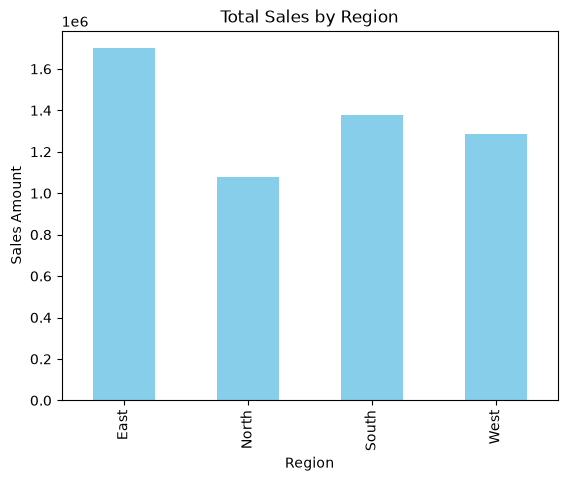

In [ ]:
#Visualize sales by region
region_sales.plot(kind='bar', color='skyblue')

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales Amount")
plt.show()

In [7]:
print("Top Region:", region_sales.idxmax())
print("Highest Sales:", region_sales.max())

Top Region: East
Highest Sales: 1698905.09


In [8]:
#sales by region and product category
category_sales = df.groupby(
    ['Region', 'ProductCategory']
)['SalesAmount'].sum().unstack()

print(category_sales)

ProductCategory   Clothing  Electronics  Furniture  Groceries
Region                                                       
East             170426.18   1181603.03  324492.99   22382.89
North             88969.85    610659.57  354800.79   21751.24
South            130530.86    835316.94  387559.17   23665.60
West             173872.12    736480.36  357921.97   16647.86


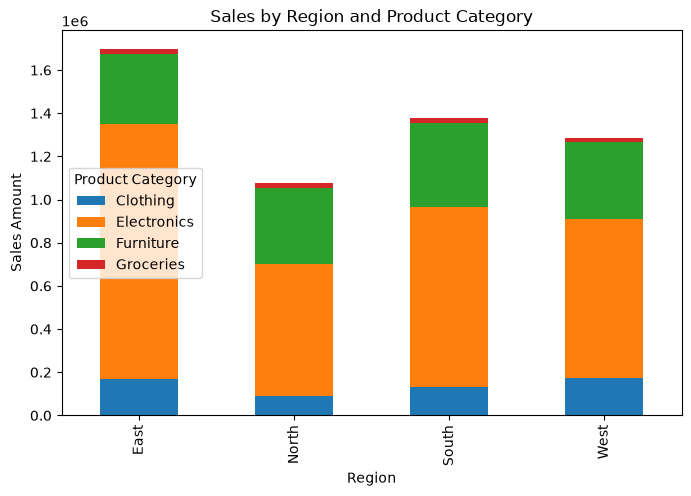

In [9]:
#stacked bar chart
category_sales.plot(kind='bar', stacked=True, figsize=(8,5))

plt.title("Sales by Region and Product Category")
plt.xlabel("Region")
plt.ylabel("Sales Amount")
plt.legend(title="Product Category")
plt.show()

In [10]:
print("Total Sales:", df['SalesAmount'].sum())
print("\nRegion-wise Sales:\n", region_sales)
print("\nTop Performing Region:", region_sales.idxmax())
print("\nCategory-wise Sales:\n", category_sales)

Total Sales: 5437081.42

Region-wise Sales:
 Region
East     1698905.09
North    1076181.45
South    1377072.57
West     1284922.31
Name: SalesAmount, dtype: float64

Top Performing Region: East

Category-wise Sales:
 ProductCategory   Clothing  Electronics  Furniture  Groceries
Region                                                       
East             170426.18   1181603.03  324492.99   22382.89
North             88969.85    610659.57  354800.79   21751.24
South            130530.86    835316.94  387559.17   23665.60
West             173872.12    736480.36  357921.97   16647.86
